# SHAI Music Genre Classification


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
sns.set_style('whitegrid')
%matplotlib inline

## 1. Load Data

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
print(train.shape, test.shape)
train.head()

(14396, 18) (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


## 2. EDA

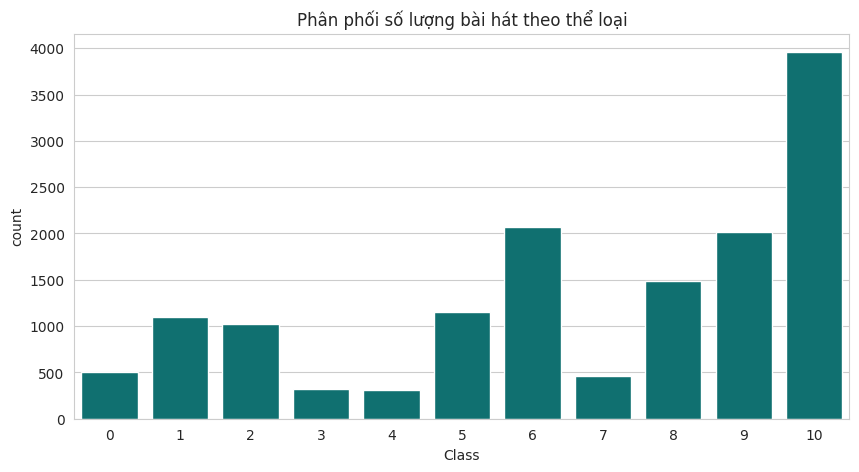

In [3]:
plt.figure(figsize=(10,5))
order = train['Class'].value_counts().sort_index().index
sns.countplot(data=train, x='Class', order=order, color='teal')
plt.title('Phân phối số lượng bài hát theo thể loại'); plt.show()

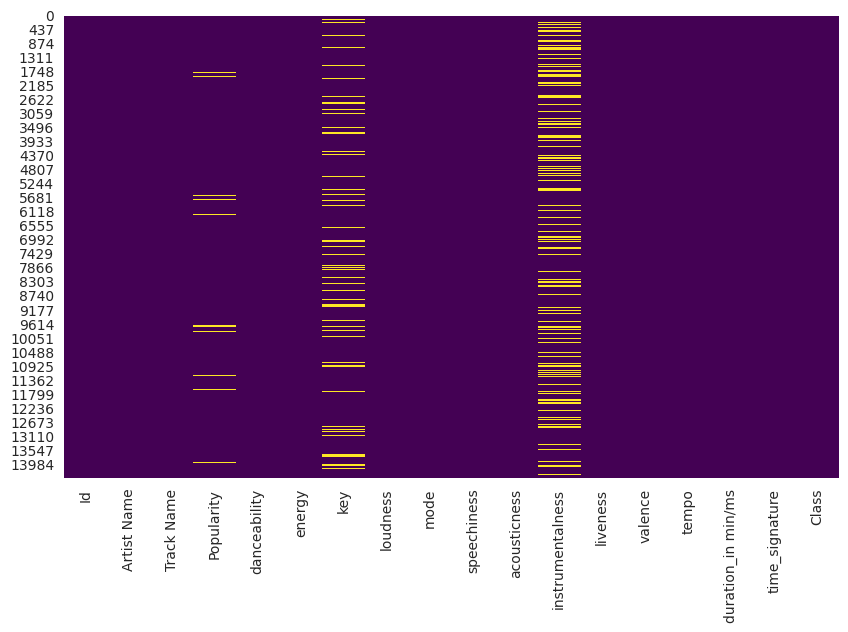

Id                       0
Artist Name              0
Track Name               0
Popularity             333
danceability             0
energy                   0
key                   1609
loudness                 0
mode                     0
speechiness              0
acousticness             0
instrumentalness      3541
liveness                 0
valence                  0
tempo                    0
duration_in min/ms       0
time_signature           0
Class                    0
dtype: int64

In [4]:
plt.figure(figsize=(10,6)); sns.heatmap(train.isnull(), cbar=False, cmap='viridis'); plt.show()
train.isnull().sum()

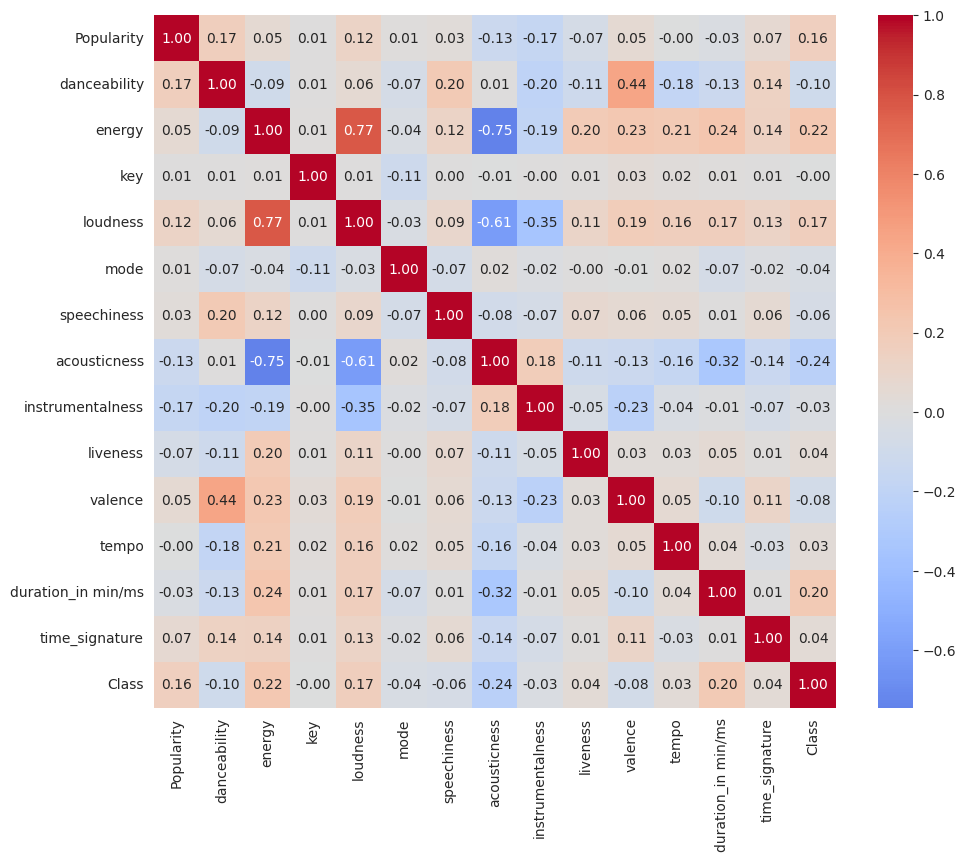

In [5]:
num_cols = ['Popularity','danceability','energy','key','loudness','mode','speechiness',
            'acousticness','instrumentalness','liveness','valence','tempo',
            'duration_in min/ms','time_signature']
corr = train[num_cols+['Class']].corr()
plt.figure(figsize=(11,9)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()

## 3. Xử lý dữ liệu (Data Preparation)
Một số giá trị `duration_in min/ms` ở dạng phút (số nhỏ <1000) thay vì mili-giây -> quy đổi đồng nhất. Điền giá trị thiếu (Popularity, key, instrumentalness) bằng median của tập train.

In [6]:
def fix_duration(df):
    df = df.copy()
    mask = df['duration_in min/ms'] < 1000
    df.loc[mask, 'duration_in min/ms'] = df.loc[mask, 'duration_in min/ms'] * 60000
    return df.rename(columns={'duration_in min/ms': 'duration_ms'})

train_feat = fix_duration(train)
test_feat = fix_duration(test)
drop_cols = ['Id','Artist Name','Track Name']
y = train_feat['Class'].copy(); test_ids = test_feat['Id'].copy()
X_train_full = train_feat.drop(columns=drop_cols+['Class'], errors='ignore')
X_test_final = test_feat.drop(columns=drop_cols, errors='ignore')
for c in X_train_full.columns:
    if X_train_full[c].isnull().any():
        med = X_train_full[c].median()
        X_train_full[c] = X_train_full[c].fillna(med)
        X_test_final[c] = X_test_final[c].fillna(med)
print(X_train_full.shape, X_test_final.shape)

(14396, 14) (3600, 14)


## 4. Train/Validation Split (stratified)

In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_full, y, test_size=0.2, random_state=42, stratify=y)

## 5. Modeling: Random Forest Classifier

In [8]:
rf = RandomForestClassifier(n_estimators=400, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_tr, y_tr)
rf_pred = rf.predict(X_val)
rf_acc = accuracy_score(y_val, rf_pred); rf_f1 = f1_score(y_val, rf_pred, average='macro')
print(f'RF -> Accuracy {rf_acc:.4f}  F1-macro {rf_f1:.4f}')

RF -> Accuracy 0.4576  F1-macro 0.4283


## 6. Modeling: Gradient Boosting Classifier

In [9]:
gbc = GradientBoostingClassifier(n_estimators=300, learning_rate=0.08, max_depth=3, random_state=42)
gbc.fit(X_tr, y_tr)
gbc_pred = gbc.predict(X_val)
gbc_acc = accuracy_score(y_val, gbc_pred); gbc_f1 = f1_score(y_val, gbc_pred, average='macro')
print(f'GBC -> Accuracy {gbc_acc:.4f}  F1-macro {gbc_f1:.4f}')

GBC -> Accuracy 0.4740  F1-macro 0.4451


## 7. So sánh mô hình & Ma trận nhầm lẫn

In [10]:
pd.DataFrame({'Model':['Random Forest','Gradient Boosting'],'Accuracy':[rf_acc,gbc_acc],'F1-macro':[rf_f1,gbc_f1]})

,Model,Accuracy,F1-macro
0,Random Forest,0.457639,0.428350
1,Gradient Boosting,0.473958,0.445076


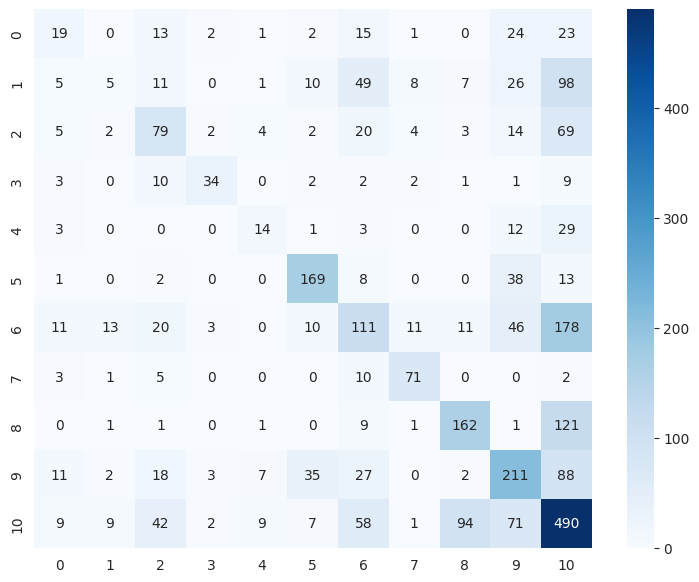

In [11]:
best_pred = gbc_pred if gbc_acc > rf_acc else rf_pred
cm = confusion_matrix(y_val, best_pred)
plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues'); plt.show()

## 8. Huấn luyện trên toàn bộ train & Dự đoán tập Test

In [12]:
best_model = gbc if gbc_acc > rf_acc else rf
best_model.fit(X_train_full, y)
test_pred = best_model.predict(X_test_final)
submission = pd.DataFrame({'Id': test_ids, 'Class': test_pred})
submission.to_csv('submission.csv', index=False)
submission.head()

,Id,Class
0,14397,6
1,14398,6
2,14399,9
3,14400,10
4,14401,5


## 9. Kết luận
Gradient Boosting Classifier cho Accuracy/F1-macro cao hơn Random Forest.